# Customer retention and lifetime value: which customers are worth keeping?

**Business question.** Most customers buy once and never return, while a small group drives most of the
revenue. To decide where retention and marketing effort should go, the business needs to know, for every
customer, **how likely they are to still be active** and **how much they are likely to spend next**.

**Data.** The CDNOW transaction log: 69,659 purchases by 23,570 customers who first bought between January and
March 1997, followed until June 1998. It is the standard public benchmark for customer-base models.

**Approach**
1. Describe retention by monthly cohort (SQL).
2. Fit two probabilistic models on the first 39 weeks only: **BG/NBD** (how often each customer buys, and
   whether they have quietly left) and **Gamma-Gamma** (how much they spend per purchase).
3. **Validate on the following 39 weeks**, which the models never saw, against two simple baselines.
4. Refit on all the data and estimate each customer's 12-month value, then segment customers by value and risk.

**Result in one line.** On 39 weeks of unseen data, the model gives the most accurate forecasts of the
approaches tested: lowest error per customer (RMSE 1.73 vs 2.16 for a naive repeat-rate forecast) and a total
14% below actual, against 47% above for the naive forecast. The top 10% of customers hold **about 65% of
predicted 12-month value**, and 1,128 historically high-value customers are now more likely gone than active,
a natural group for a re-engagement test.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from prodanalytics.clv import BGNBD, GammaGamma, customer_lifetime_value, rfm_summary
from prodanalytics.data import load_cdnow_transactions
from prodanalytics import plotting as P

P.apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Data

In [2]:
tx = load_cdnow_transactions()   # also writes data/processed/cdnow_transactions.csv for the SQL below
print(f"{len(tx):,} transactions | {tx.customer_id.nunique():,} customers | "
      f"{tx.date.min():%d %b %Y} to {tx.date.max():%d %b %Y} | revenue ${tx.value.sum():,.0f}")
purchases_per_customer = tx.groupby("customer_id").date.nunique()
print(f"customers who only ever bought on one day: {(purchases_per_customer == 1).mean():.1%}")

69,659 transactions | 23,570 customers | 01 Jan 1997 to 30 Jun 1998 | revenue $2,500,316
customers who only ever bought on one day: 51.1%


## 2. Cohort retention (SQL)

In [3]:
cohorts = duckdb.sql(open("sql/cohort_retention.sql").read()).df()
grid = cohorts.pivot(index="cohort_month", columns="months_since_first", values="retention")
grid.index = pd.to_datetime(grid.index).strftime("%b %Y")
grid.iloc[:, :8]

months_since_first,0,1,2,3,4,5,6,7
cohort_month,,,,,,,,
Jan 1997,1.000,0.147,0.123,0.103,0.086,0.094,0.092,0.074
Feb 1997,1.000,0.155,0.116,0.092,0.100,0.093,0.074,0.073
Mar 1997,1.000,0.142,0.104,0.104,0.093,0.078,0.077,0.080


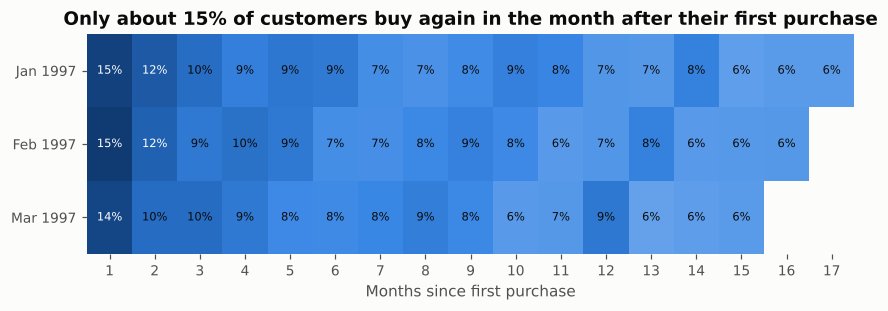

In [4]:
fig, ax = plt.subplots(figsize=(9, 2.6))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blues", P.SEQ_BLUES)
show = grid.iloc[:, 1:]   # month 0 is 100% by definition
im = ax.imshow(show.values, aspect="auto", cmap=cmap, vmin=0, vmax=0.16)
ax.set_xticks(range(show.shape[1]), show.columns)
ax.set_yticks(range(show.shape[0]), show.index)
for i in range(show.shape[0]):
    for j in range(show.shape[1]):
        v = show.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.11 else P.TEXT)
ax.set_xlabel("Months since first purchase")
ax.set_title("Only about 15% of customers buy again in the month after their first purchase")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
P.save(fig, "clv_cohort_retention")
plt.show()

Retention drops to about 15% in the first month and then settles at roughly 6–9%. The three cohorts behave
almost identically, which supports modelling them together. Every cohort shows a mild lift in October to
December 1997 (months 9–11, 8–10 and 7–9 respectively), possibly a seasonal effect; one year of data cannot
separate that from one-off events such as promotions.

## 3. Model on the first 39 weeks, test on the next 39

* **BG/NBD** treats each customer as buying at their own steady rate while active, with some chance of
  silently dropping out after each purchase. It estimates both from recency (when they last bought),
  frequency (how many repeat purchases) and tenure.
* **Gamma-Gamma** estimates each customer's typical spend, shrinking customers with few purchases towards
  the population average so one large order does not dominate.
* **Baselines:** (1) every customer keeps buying at their historical repeat rate, which is what a simple
  spreadsheet forecast would do; (2) nobody buys again, a useful floor because most customers do not return.

In [5]:
calibration_end = pd.Timestamp("1997-09-30")
holdout_end = pd.Timestamp("1998-06-30")
holdout_weeks = (holdout_end - calibration_end) / pd.Timedelta(days=7)

cal = rfm_summary(tx, "customer_id", "date", "value", calibration_end)
bgnbd = BGNBD().fit(cal.frequency, cal.recency, cal["T"])
gg = GammaGamma().fit(cal.frequency, cal.monetary)
print("BG/NBD:", {k: round(float(v), 3) for k, v in bgnbd.params.items()})
print("Gamma-Gamma:", {k: round(float(v), 3) for k, v in gg.params.items()})
print(f"holdout length: {holdout_weeks:.0f} weeks")

BG/NBD: {'r': 0.252, 'alpha': 4.789, 'a': 0.723, 'b': 2.161}
Gamma-Gamma: {'p': 6.275, 'q': 3.624, 'gamma': 14.984}
holdout length: 39 weeks


In [6]:
daily = tx.groupby(["customer_id", "date"], as_index=False).value.sum()
holdout = (daily[(daily.date > calibration_end) & (daily.date <= holdout_end)]
           .groupby("customer_id").agg(actual_purchases=("date", "size"), actual_value=("value", "sum")))
cal = cal.join(holdout).fillna({"actual_purchases": 0, "actual_value": 0})

cal["model_purchases"] = bgnbd.expected_purchases(holdout_weeks, cal.frequency, cal.recency, cal["T"])
cal["model_value"] = cal.model_purchases * gg.expected_spend(cal.frequency, cal.monetary)
cal["naive_purchases"] = cal.frequency / cal["T"] * holdout_weeks
cal["naive_value"] = cal.naive_purchases * cal.monetary

### Validation 1: customer-level accuracy

In [7]:
cal["zero_purchases"] = 0.0

def score(pred_col, value_col=None):
    err = cal[pred_col] - cal.actual_purchases
    out = {
        "root mean squared error": np.sqrt((err ** 2).mean()),
        "mean absolute error": err.abs().mean(),
        "total predicted purchases": cal[pred_col].sum(),
        "aggregate error": cal[pred_col].sum() / cal.actual_purchases.sum() - 1,
        "rank correlation with actual (Spearman)": np.nan,
        "holdout revenue captured by top 10%": np.nan,
    }
    if value_col:
        ranked = cal.sort_values(value_col, ascending=False)
        out["rank correlation with actual (Spearman)"] = spearmanr(cal[pred_col], cal.actual_purchases).statistic
        out["holdout revenue captured by top 10%"] = (ranked.actual_value.iloc[: len(ranked) // 10].sum()
                                                       / cal.actual_value.sum())
    return out

results = pd.DataFrame({"BG/NBD + Gamma-Gamma": score("model_purchases", "model_value"),
                        "Naive repeat rate": score("naive_purchases", "naive_value"),
                        "Nobody returns": score("zero_purchases")})
print(f"actual holdout purchases: {cal.actual_purchases.sum():,.0f}")
results

actual holdout purchases: 19,684


,BG/NBD + Gamma-Gamma,Naive repeat rate,Nobody returns
root mean squared error,1.733,2.158,2.467
mean absolute error,0.819,1.038,0.835
total predicted purchases,"16,873.733","29,010.645",0.000
aggregate error,-0.143,0.474,-1.000
rank correlation with actual (Spearman),0.442,0.485,NaN
holdout revenue captured by top 10%,0.516,0.504,NaN


* **Accuracy.** The model has the lowest RMSE (1.73, against 2.16 for the repeat-rate forecast and 2.47 for
  "nobody returns"), and its total is far closer to reality. The repeat-rate forecast overstates future purchases
  by almost half because it assumes nobody ever leaves.
* **Why not mean absolute error?** Most customers buy nothing in the holdout, so MAE rewards forecasting
  zero: "nobody returns" scores 0.84 against the model's 0.82. RMSE, which penalises large misses, is the
  fairer yardstick here.
* **Ranking.** For ordering customers alone, the simple repeat rate is slightly better (Spearman 0.49 vs 0.44).
  Both flag a top 10% that goes on to generate about half of holdout revenue.

The model's real advantage is **far more realistic forecast levels**, in total and across customer groups, plus
an estimate of whether each customer is still active, which a repeat rate cannot give. It is not perfect: it
**under**-forecasts the total by 14% and under-predicts light repeat buyers. Validations 2 and 3 show where the
gap comes from.

### Validation 2: purchases by customer history

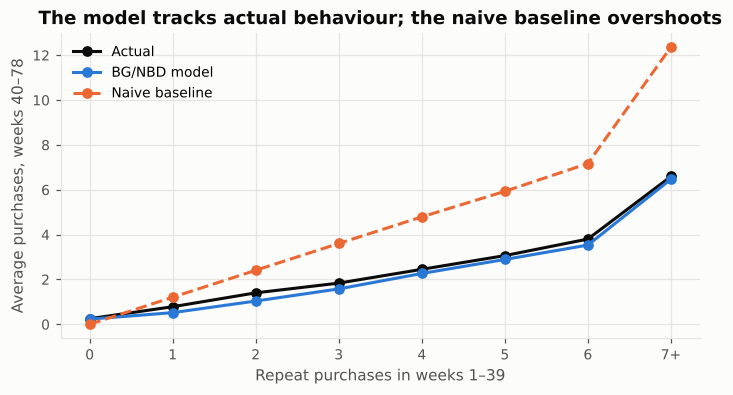

,actual_purchases,model_purchases,naive_purchases
calibration_purchases,,,
0,0.251,0.231,0.000
1,0.784,0.520,1.207
2,1.403,1.037,2.408
3,1.837,1.579,3.604
4,2.451,2.267,4.791
5,3.063,2.892,5.929
6,3.801,3.533,7.171
7,6.591,6.469,12.361


In [8]:
cal["calibration_purchases"] = cal.frequency.clip(upper=7)
by_freq = cal.groupby("calibration_purchases")[["actual_purchases", "model_purchases", "naive_purchases"]].mean()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = by_freq.index
ax.plot(x, by_freq.actual_purchases, "o-", color=P.TEXT, label="Actual", ms=6)
ax.plot(x, by_freq.model_purchases, "o-", color=P.CONTROL, label="BG/NBD model", ms=6)
ax.plot(x, by_freq.naive_purchases, "o--", color=P.TREATMENT, label="Naive baseline", ms=6)
ax.set_xticks(x, [str(i) if i < 7 else "7+" for i in x])
ax.set_xlabel("Repeat purchases in weeks 1\u201339")
ax.set_ylabel("Average purchases, weeks 40\u201378")
ax.set_title("The model tracks actual behaviour; the naive baseline overshoots")
ax.legend(loc="upper left")
P.save(fig, "clv_holdout_by_frequency")
plt.show()
by_freq

### Validation 3: weekly repeat purchases over time

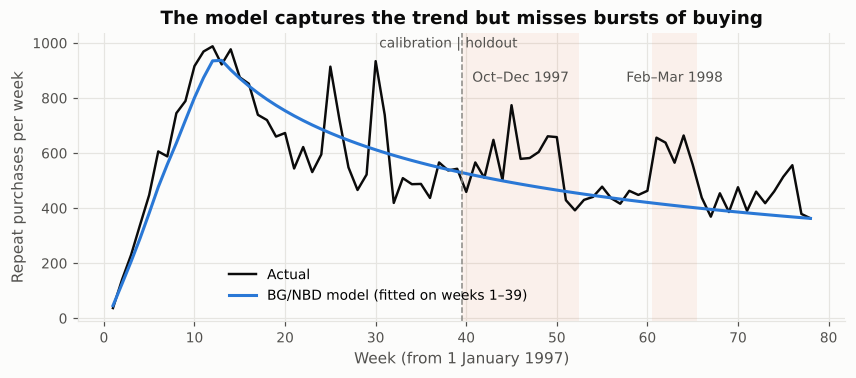

holdout shortfall on the weekly tracking curve: 2,859 purchases
  Oct-Dec 1997 (13 weeks): 1,012 (35%)
  late Feb-Mar 1998 (5 weeks): 1,033 (36%)


In [9]:
first_purchase_week = ((cal.first_purchase - pd.Timestamp("1997-01-01")).dt.days / 7).to_numpy()
weeks = np.arange(1, 79)
expected_cum = np.array([bgnbd.expected_purchases_new_customer(np.clip(w - first_purchase_week, 0, None)).sum()
                         for w in weeks])
expected_weekly = np.diff(np.concatenate([[0], expected_cum]))

first = daily.groupby("customer_id").date.transform("min")
repeat = daily[daily.date > first]
actual_weekly = (repeat.assign(week=((repeat.date - pd.Timestamp("1997-01-01")).dt.days // 7) + 1)
                 .groupby("week").size().reindex(weeks, fill_value=0))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(weeks, actual_weekly.values, color=P.TEXT, lw=1.6, label="Actual")
ax.plot(weeks, expected_weekly, color=P.CONTROL, lw=2, label="BG/NBD model (fitted on weeks 1\u201339)")
ax.axvline(39.5, color=P.NEUTRAL, ls="--", lw=1)
ax.annotate("calibration | holdout", (39.5, ax.get_ylim()[1] * 0.95), xytext=(-54, 0), textcoords="offset points",
            fontsize=9, color=P.TEXT_2)
ax.axvspan(39.5, 52.5, color=P.TREATMENT, alpha=0.08, lw=0)
ax.annotate("Oct\u2013Dec 1997", (46, ax.get_ylim()[1] * 0.83), ha="center", fontsize=9, color=P.TEXT_2)
ax.axvspan(60.5, 65.5, color=P.TREATMENT, alpha=0.08, lw=0)
ax.annotate("Feb\u2013Mar 1998", (63, ax.get_ylim()[1] * 0.83), ha="center", fontsize=9, color=P.TEXT_2)
ax.set_xlabel("Week (from 1 January 1997)")
ax.set_ylabel("Repeat purchases per week")
ax.set_title("The model captures the trend but misses bursts of buying")
ax.legend(loc="lower left", bbox_to_anchor=(0.18, 0.02))
P.save(fig, "clv_weekly_tracking")
plt.show()
def shortfall(first_week, last_week):
    # Actual minus modelled repeat purchases over a range of weeks (week 40 starts on 1 Oct 1997).
    return actual_weekly.loc[first_week:last_week].sum() - expected_weekly[first_week - 1:last_week].sum()

total_gap = shortfall(40, 78)
holiday = shortfall(40, 52)     # 1 Oct - 30 Dec 1997
spring = shortfall(61, 65)      # 25 Feb - 31 Mar 1998
print(f"holdout shortfall on the weekly tracking curve: {total_gap:,.0f} purchases")
print(f"  Oct-Dec 1997 (13 weeks): {holiday:,.0f} ({holiday / total_gap:.0%})")
print(f"  late Feb-Mar 1998 (5 weeks): {spring:,.0f} ({spring / total_gap:.0%})")

The model follows the overall decline in repeat buying closely, but it assumes each customer buys at a steady
rate, so it cannot anticipate bursts of activity. Two bursts identified from the chart, October–December 1997
and late February–March 1998, account for about 70% of the holdout shortfall in 18 of its 39 weeks. With only one
year of data, I cannot tell whether they are seasonal or one-off events such as promotions. Validation 2 adds that
the model under-predicts most for light repeat buyers (one or two earlier purchases). Before using this in
production, I would add time-varying covariates (seasonality, marketing activity) and re-validate on more history.
The errors are systematic and explainable, which shows exactly where the model needs extending.

### Checking a key assumption

Gamma-Gamma assumes that how much a customer spends per purchase is unrelated to how often they buy.

In [10]:
repeaters = cal[(cal.frequency > 0) & (cal.monetary > 0)]
rho = spearmanr(repeaters.frequency, repeaters.monetary).statistic
print(f"Spearman correlation between purchase frequency and average spend (repeat buyers): {rho:.2f}")

Spearman correlation between purchase frequency and average spend (repeat buyers): 0.20


The relationship is weak (about 0.2), so the assumption holds approximately but not perfectly; this is noted in
the limitations.

## 4. Business use: 12-month value and who to prioritise

Refit both models on all 78 weeks, then estimate each customer's discounted revenue over the next 12 months
(1% monthly discount rate).

In [11]:
full = rfm_summary(tx, "customer_id", "date", "value", holdout_end)
bg_full = BGNBD().fit(full.frequency, full.recency, full["T"])
gg_full = GammaGamma().fit(full.frequency, full.monetary)
full["p_alive"] = bg_full.prob_alive(full.frequency, full.recency, full["T"])
full["clv_12m"] = customer_lifetime_value(bg_full, gg_full, full, months=12, monthly_discount=0.01)
full["historical_value"] = tx.groupby("customer_id").value.sum()

ranked = full.sort_values("clv_12m", ascending=False)
share = ranked.clv_12m.cumsum() / ranked.clv_12m.sum()
n = len(ranked)
print(f"total predicted 12-month value: ${full.clv_12m.sum():,.0f} (median customer ${full.clv_12m.median():.2f})")
for q in (0.01, 0.05, 0.10, 0.20):
    print(f"top {q:.0%} of customers -> {share.iloc[int(n * q) - 1]:.1%} of predicted value")
one_time = full.frequency == 0
print(f"one-time buyers: {one_time.mean():.1%} of customers, {full.loc[one_time, 'clv_12m'].sum() / full.clv_12m.sum():.1%} of predicted value")

total predicted 12-month value: $779,641 (median customer $5.94)
top 1% of customers -> 22.9% of predicted value
top 5% of customers -> 49.3% of predicted value
top 10% of customers -> 64.7% of predicted value
top 20% of customers -> 80.0% of predicted value
one-time buyers: 51.1% of customers, 8.8% of predicted value


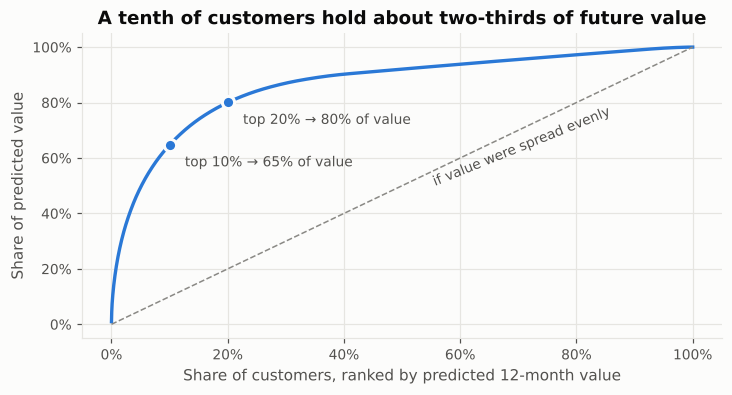

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
pct = np.arange(1, n + 1) / n
ax.plot(pct, share.values, color=P.CONTROL, lw=2.2)
ax.plot([0, 1], [0, 1], color=P.NEUTRAL, ls="--", lw=1)
for q in (0.10, 0.20):
    v = share.iloc[int(n * q) - 1]
    ax.plot(q, v, "o", color=P.CONTROL, ms=8, mec=P.SURFACE, mew=2)
    ax.annotate(f"top {q:.0%} \u2192 {v:.0%} of value", (q, v), xytext=(10, -14), textcoords="offset points",
                fontsize=9, color=P.TEXT_2)
ax.annotate("if value were spread evenly", (0.55, 0.5), fontsize=9, color=P.TEXT_2, rotation=22)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share of customers, ranked by predicted 12-month value")
ax.set_ylabel("Share of predicted value")
ax.set_title("A tenth of customers hold about two-thirds of future value")
P.save(fig, "clv_value_concentration")
plt.show()

In [13]:
high_value = full.historical_value >= full.historical_value.quantile(0.8)
at_risk = high_value & (full.p_alive < 0.5)
print(f"historically high-value customers (top 20% by spend): {high_value.sum():,}")
print(f"  of whom the model now rates as more likely gone than active: {at_risk.sum():,} "
      f"(they spent ${full.loc[at_risk, 'historical_value'].sum():,.0f} to date)")

segments = pd.cut(full.clv_12m.rank(pct=True), [0, 0.5, 0.8, 0.9, 1.0],
                  labels=["Bottom 50%", "50-80%", "80-90%", "Top 10%"])
full.groupby(segments, observed=True).agg(customers=("clv_12m", "size"), avg_clv_12m=("clv_12m", "mean"),
                                          avg_p_alive=("p_alive", "mean"),
                                          avg_repeat_purchases=("frequency", "mean"))

historically high-value customers (top 20% by spend): 4,715
  of whom the model now rates as more likely gone than active: 1,128 (they spent $355,918 to date)


,customers,avg_clv_12m,avg_p_alive,avg_repeat_purchases
clv_12m,,,,
Bottom 50%,11781,5.255,0.868,0.324
50-80%,7075,13.258,0.682,1.279
80-90%,2357,50.609,0.738,3.767
Top 10%,2357,214.104,0.848,9.451


## 5. Recommendations

1. **Prioritise the top 10% for retention effort.** They hold about two-thirds of predicted value. High value
   is not the same as being responsive to a campaign, so any retention offer should be tested against a
   randomised holdout.
2. **Test a win-back campaign for high-value customers who have gone quiet.** 1,128 customers in the top fifth
   by historical spend now have a better-than-even chance of having left. They are a natural target group, and
   a randomised holdout would show whether contacting them changes behaviour.
3. **Investigate what earns a second purchase.** Half of customers never buy again and retention collapses
   after the first month, so the first-to-second purchase step is where the most customers are lost.
   Understanding what drives it, and testing changes to onboarding, is a promising lever.
4. **Plan for bursts of demand.** The model's main misses are short bursts of buying; with more years of data,
   test whether these are seasonal and add an adjustment to the forecast.

**Limitations.** The model uses revenue, not profit, and has no customer attributes (channel, demographics,
product mix). It assumes one-time buyers are still active, which overstates their survival. The Gamma-Gamma
model assumes spend per purchase is independent of purchase frequency; the check above shows a weak positive
relationship, so value estimates for the most frequent buyers may be slightly conservative. In a bank, the same
framework applies, with value driven by product revenue (interchange, lending, subscriptions) net of cost, and
with customer attributes added as covariates. The calibration-then-holdout discipline used here carries over
unchanged.